In [1]:

# ==================================================
# LSTM PRACTICAL: TIME SERIES FORECASTING
# ==================================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping




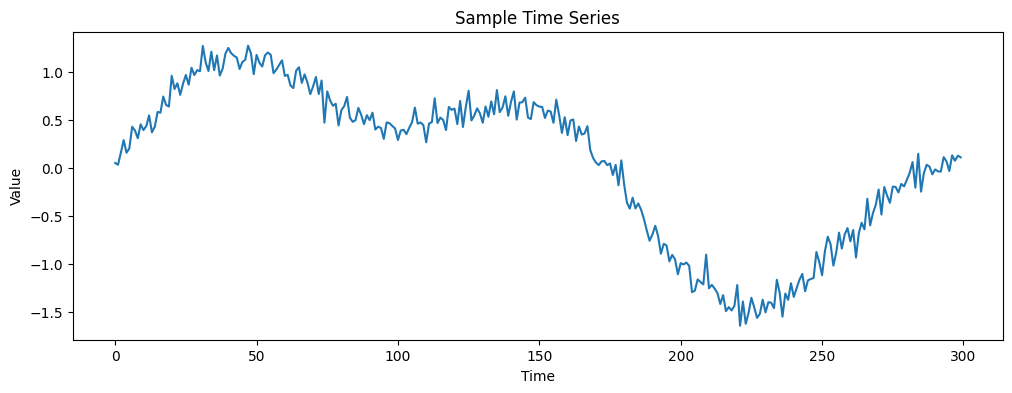

In [2]:
# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# STEP 1: Create sample time-series data
time = np.arange(2000)

series = (
    np.sin(0.02 * time)
    + 0.5 * np.sin(0.05 * time)
    + 0.1 * np.random.randn(2000)
)

series = series.reshape(-1, 1)

plt.figure(figsize=(12, 4))
plt.plot(series[:300])
plt.title("Sample Time Series")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()



In [3]:
# STEP 2: Chronological train/test split
split_index = int(len(series) * 0.80)

# Fit scaler only on training period
scaler = MinMaxScaler()
scaler.fit(series[:split_index])

scaled_series = scaler.transform(series)

# STEP 3: Create sequences
LOOK_BACK = 30

X, y, target_indices = [], [], []

for i in range(LOOK_BACK, len(scaled_series)):
    X.append(scaled_series[i-LOOK_BACK:i, 0])
    y.append(scaled_series[i, 0])
    target_indices.append(i)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
target_indices = np.array(target_indices)

# Required input shape: samples, time steps, features
X = X.reshape(X.shape[0], LOOK_BACK, 1)

train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)



X_train: (1570, 30, 1)
X_test: (400, 30, 1)


In [4]:
# STEP 4: Build the LSTM model
model = Sequential([
    Input(shape=(LOOK_BACK, 1)),
    LSTM(32),
    Dense(1)
])

model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# STEP 5: Compile
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# STEP 6: Train
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)



Epoch 1/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.1324 - mae: 0.2682 - val_loss: 0.0112 - val_mae: 0.0812
Epoch 2/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0108 - mae: 0.0843 - val_loss: 0.0076 - val_mae: 0.0658
Epoch 3/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0071 - mae: 0.0679 - val_loss: 0.0057 - val_mae: 0.0583
Epoch 4/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0057 - mae: 0.0612 - val_loss: 0.0047 - val_mae: 0.0547
Epoch 5/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0050 - mae: 0.0573 - val_loss: 0.0041 - val_mae: 0.0518
Epoch 6/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0043 - mae: 0.0536 - val_loss: 0.0037 - val_mae: 0.0487
Epoch 7/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0037 - mae: 0.0494 - val_loss: 0.0032 - val_mae: 0.0453
Epoch 8/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0030 - mae: 0.0445 - val_loss: 0.0027 - val_mae: 0.0414
Epoch 9/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.002

In [6]:
# STEP 7: Predict on unseen test samples
pred_scaled = model.predict(X_test, verbose=0)

# Convert to original data scale
pred = scaler.inverse_transform(pred_scaled).flatten()
actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

# STEP 8: Evaluate
mae = mean_absolute_error(actual, pred)
rmse = np.sqrt(mean_squared_error(actual, pred))

print("Test MAE:", round(mae, 4))
print("Test RMSE:", round(rmse, 4))



Test MAE: 0.091
Test RMSE: 0.1161


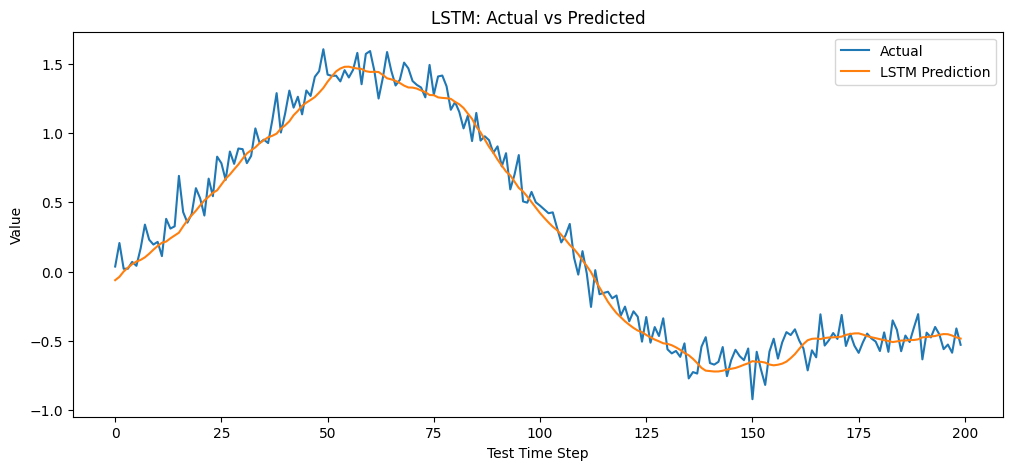

In [7]:
# STEP 9: Plot actual vs predicted
plt.figure(figsize=(12, 5))
plt.plot(actual[:200], label="Actual")
plt.plot(pred[:200], label="LSTM Prediction")
plt.title("LSTM: Actual vs Predicted")
plt.xlabel("Test Time Step")
plt.ylabel("Value")
plt.legend()
plt.show()



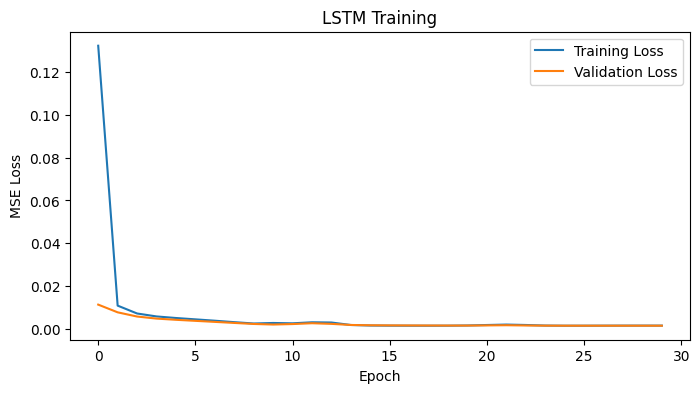

In [8]:
# STEP 10: Plot training and validation loss
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Training")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()



In [9]:
# STEP 11: Predict next value using latest 30 points
last_sequence = scaled_series[-LOOK_BACK:]
last_sequence = last_sequence.reshape(1, LOOK_BACK, 1)

next_scaled = model.predict(last_sequence, verbose=0)
next_value = scaler.inverse_transform(next_scaled)[0, 0]

print("Next predicted value:", round(float(next_value), 4))

Next predicted value: 0.4603
